# Actividad 2: Gráficos y funciones en R (aves de Esmeraldas, Ecuador)

**Curso:** Optimización de la gestión de ecosistemas marinos y recursos pesqueros en Latinoamérica mediante ciencia abierta (OHW en español, edición 2026)  
**Autor:** Kevin Tapia-Rodriguez  
**Lenguaje:** R

**Objetivos de la actividad:**
1. Crear gráficos.
2. Definir funciones sencillas.

**Datos:** se usa la misma muestra anonimizada de la Actividad 1 (`data/muestra/ebd_muestra_esmeraldas.csv`): 102 registros de eBird de 6 listas de Esmeraldas (2021–2026). Estos datos forman parte del trabajo del informe técnico de aves marinas del IPIAP; la descripción completa está en `01_exploracion_ebird.ipynb`.

## 1. Paquetes y datos

In [1]:
suppressPackageStartupMessages({
  library(readr)
  library(dplyr)
  library(ggplot2)
})

ebd <- read_csv("../data/muestra/ebd_muestra_esmeraldas.csv",
                col_types = cols(.default = col_character()))

# Carpeta para guardar las figuras
dir.create("../figuras", showWarnings = FALSE)

cat("Registros:", nrow(ebd), "\n")

Registros: 102 


## 2. Funciones

Cada función tiene una documentación corta que describe qué hace, qué recibe y qué devuelve.

### 2.1 Convertir conteos a números

En eBird, `OBSERVATION COUNT` es texto: puede ser un número o `"X"` (especie presente, pero sin contar). Esta función lo convierte a número y deja `"X"` como `NA`.

In [2]:
#' Convertir conteos de eBird a número
#'
#' @param conteo Vector de texto con conteos (números o "X").
#' @return Vector numérico; los "X" se convierten en NA.
#' @examples convertir_conteo(c("3", "X", "12"))
convertir_conteo <- function(conteo) {
  conteo[conteo == "X"] <- NA
  as.numeric(conteo)
}

convertir_conteo(c("3", "X", "12"))

[1]  3 NA 12

### 2.2 Resumir especies

Calcula, para cada especie, el total de individuos y en cuántas listas aparece, y devuelve las `n` más abundantes.

In [3]:
#' Resumen de abundancia por especie
#'
#' @param datos Tabla del EBD (columnas COMMON NAME, SCIENTIFIC NAME,
#'   OBSERVATION COUNT y SAMPLING EVENT IDENTIFIER).
#' @param n Número de especies a devolver (por defecto 10).
#' @return Tabla con individuos y número de listas por especie, ordenada
#'   de mayor a menor abundancia.
resumir_especies <- function(datos, n = 10) {
  datos %>%
    mutate(individuos = convertir_conteo(`OBSERVATION COUNT`)) %>%
    group_by(`COMMON NAME`, `SCIENTIFIC NAME`) %>%
    summarise(individuos = sum(individuos, na.rm = TRUE),
              listas     = n_distinct(`SAMPLING EVENT IDENTIFIER`),
              .groups = "drop") %>%
    arrange(desc(individuos)) %>%
    head(n)
}

resumir_especies(ebd, n = 5)

COMMON NAME,SCIENTIFIC NAME,individuos,listas
<chr>,<chr>,<dbl>,<int>
Blue-footed Booby,Sula nebouxii,292,5
Semipalmated Plover,Charadrius semipalmatus,201,2
Western Cattle-Egret,Ardea ibis,100,1
Inca Tern,Larosterna inca,50,1
Black Vulture,Coragyps atratus,47,4


### 2.3 Riqueza por lista

Cuenta cuántas especies distintas se registraron en cada lista (*checklist*), junto con su fecha y protocolo.

In [4]:
#' Riqueza de especies por lista
#'
#' @param datos Tabla del EBD.
#' @return Tabla con una fila por lista: fecha, protocolo y número de especies.
riqueza_por_lista <- function(datos) {
  datos %>%
    group_by(`SAMPLING EVENT IDENTIFIER`, `OBSERVATION DATE`, `OBSERVATION TYPE`) %>%
    summarise(riqueza = n_distinct(`SCIENTIFIC NAME`), .groups = "drop") %>%
    arrange(`OBSERVATION DATE`)
}

riqueza_por_lista(ebd)

SAMPLING EVENT IDENTIFIER,OBSERVATION DATE,OBSERVATION TYPE,riqueza
<chr>,<chr>,<chr>,<int>
S104124006,2021-11-01,Traveling,36
S113025897,2022-06-15,Traveling,9
S161604587,2024-01-26,Area,8
S263890357,2025-07-29,Traveling,14
S365018290,2026-06-28,Traveling,8
S381777123,2026-08-08,Incidental,27


### 2.4 Gráfico de especies más abundantes

Función que resalta las especies focales con otro color en un gráfico de barras.

In [5]:
#' Gráfico de barras de las especies más abundantes
#'
#' @param datos Tabla del EBD.
#' @param focales Vector de nombres científicos de las especies focales a resaltar.
#' @param n Número de especies a mostrar (por defecto 10).
#' @return Objeto ggplot.
graficar_top_especies <- function(datos, focales, n = 10) {
  top <- resumir_especies(datos, n) %>%
    mutate(grupo = if_else(`SCIENTIFIC NAME` %in% focales, "Especie focal", "Otras especies"))

  ggplot(top, aes(x = individuos, y = reorder(`COMMON NAME`, individuos), fill = grupo)) +
    geom_col() +
    scale_fill_manual(values = c("Especie focal" = "#1b6ca8", "Otras especies" = "grey70")) +
    labs(title = paste("Las", n, "especies con más individuos registrados"),
         subtitle = "Muestra eBird, Esmeraldas (2021–2026)",
         x = "Individuos (suma de conteos)", y = NULL, fill = NULL) +
    theme_minimal(base_size = 12) +
    theme(legend.position = "bottom")
}

## 3. Gráficos

### 3.1 Especies más abundantes, resaltando las aves marinas focales

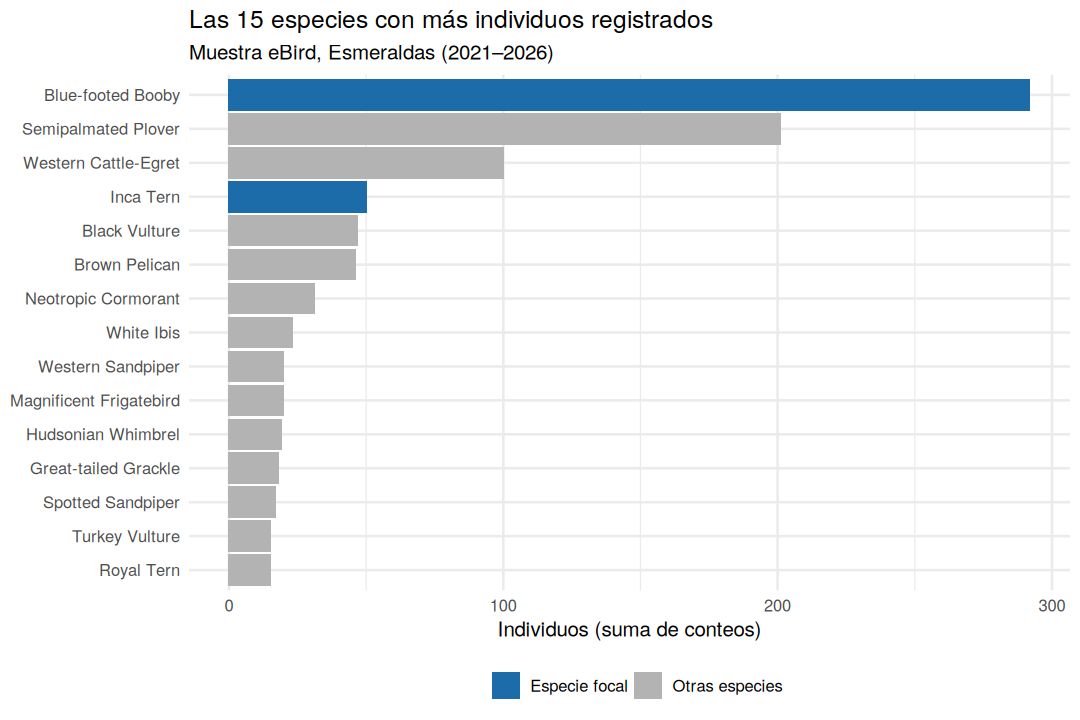

In [6]:
especies_focales <- c("Sula variegata", "Sula nebouxii", "Leucocarbo bougainvilliorum",
                      "Larosterna inca", "Ardenna grisea")

options(repr.plot.width = 9, repr.plot.height = 6)

g1 <- graficar_top_especies(ebd, focales = especies_focales, n = 15)
g1
ggsave("../figuras/top_especies.png", g1, width = 9, height = 6, dpi = 150)

### 3.2 Riqueza de especies por lista

Cada barra es una lista, coloreada según su protocolo de observación. La lista incidental (sin esfuerzo estandarizado) es la que el depurador debería filtrar.

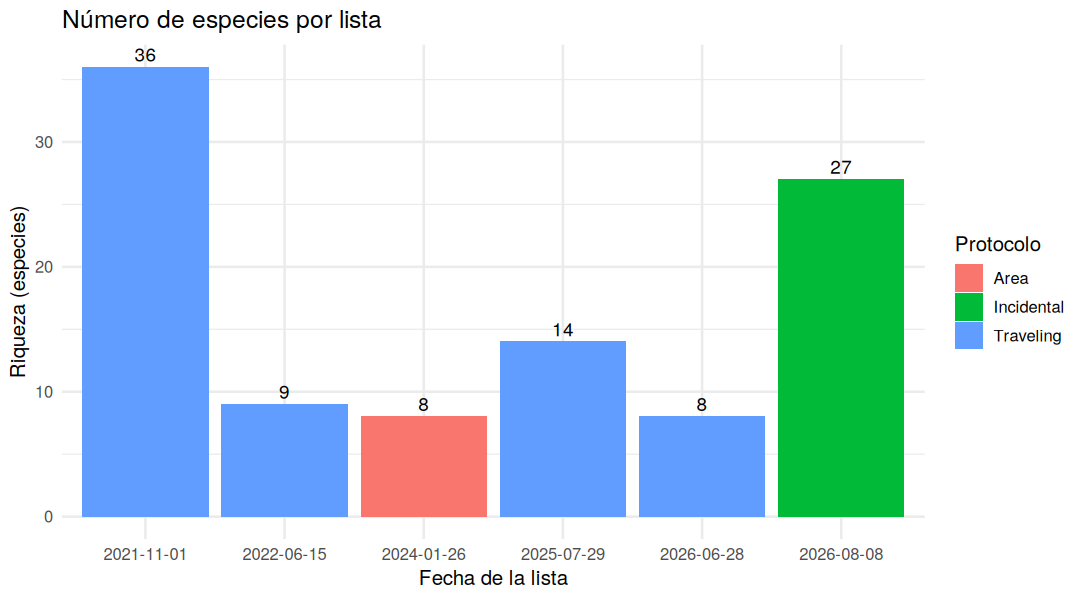

In [7]:
riq <- riqueza_por_lista(ebd)

g2 <- ggplot(riq, aes(x = `OBSERVATION DATE`, y = riqueza, fill = `OBSERVATION TYPE`)) +
  geom_col() +
  geom_text(aes(label = riqueza), vjust = -0.4) +
  labs(title = "Número de especies por lista",
       x = "Fecha de la lista", y = "Riqueza (especies)", fill = "Protocolo") +
  theme_minimal(base_size = 12)

options(repr.plot.width = 9, repr.plot.height = 5)
g2
ggsave("../figuras/riqueza_por_lista.png", g2, width = 9, height = 5, dpi = 150)

### 3.3 Ubicación de los registros de especies focales

Coordenadas de las localidades de cada lista. Los puntos azules son las listas que incluyen al menos una especie focal. Para dibujar la costa se usa `map_data()`, que necesita el paquete `maps`.

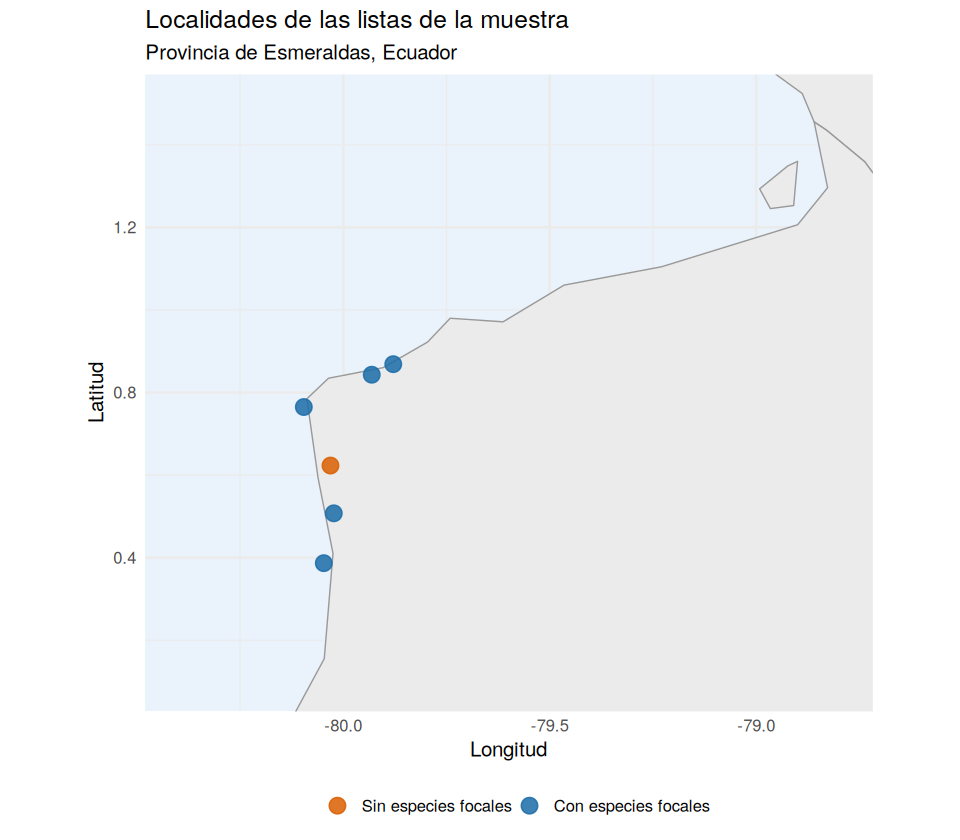

In [8]:
localidades <- ebd %>%
  mutate(focal = `SCIENTIFIC NAME` %in% especies_focales,
         LATITUDE = as.numeric(LATITUDE), LONGITUDE = as.numeric(LONGITUDE)) %>%
  group_by(`SAMPLING EVENT IDENTIFIER`, LOCALITY, LATITUDE, LONGITUDE) %>%
  summarise(con_focales = any(focal), .groups = "drop")

# Contorno de Ecuador y Colombia (requiere el paquete 'maps')
costa <- map_data("world", region = c("Ecuador", "Colombia"))

g3 <- ggplot() +
  geom_polygon(data = costa, aes(x = long, y = lat, group = group),
               fill = "grey92", color = "grey60", linewidth = 0.3) +
  geom_point(data = localidades,
             aes(x = LONGITUDE, y = LATITUDE, color = con_focales),
             size = 4, alpha = 0.85) +
  scale_color_manual(values = c("TRUE" = "#1b6ca8", "FALSE" = "#d95f02"),
                     labels = c("TRUE" = "Con especies focales", "FALSE" = "Sin especies focales")) +
  coord_quickmap(xlim = c(-80.4, -78.8), ylim = c(0.1, 1.5)) +
  labs(title = "Localidades de las listas de la muestra",
       subtitle = "Provincia de Esmeraldas, Ecuador",
       x = "Longitud", y = "Latitud", color = NULL) +
  theme_minimal(base_size = 12) +
  theme(legend.position = "bottom",
        panel.background = element_rect(fill = "#eaf3fb", color = NA))

options(repr.plot.width = 8, repr.plot.height = 7)
g3
ggsave("../figuras/localidades.png", g3, width = 8, height = 7, dpi = 150, bg = "white")

## Conclusión

- Se definieron cuatro funciones documentadas: `convertir_conteo()`, `resumir_especies()`, `riqueza_por_lista()` y `graficar_top_especies()`.
- Las funciones evitan repetir código; por ejemplo, `graficar_top_especies()` reutiliza `resumir_especies()`, que a su vez usa `convertir_conteo()`.
- Se crearon tres gráficos con `ggplot2` y se guardaron en la carpeta `figuras/`.
- En la muestra aparecen las cinco especies focales de aves marinas, sobre todo el piquero patas azules (*Sula nebouxii*).